In [1]:
import pandas as pd

df = pd.read_csv("penguins.csv")

print(df.shape)
print(df.isnull().sum())
print(df["species"].value_counts())

(344, 8)
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


Prompt log:

Prompt 1: You are helping with exploratory data analysis.
My CSV has columns:

species: object

island: object

bill_length_mm: float64

bill_depth_mm: float64

flipper_length_mm: float64

body_mass_g: float64

sex: object

year: int64

Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare flipper_length_mm across species,
(3) produce one labeled chart.
Explain each step in comments.

result: My per-species numbers match the AI's.

Prompt 2: make a better chart.

result: I ran it and it is a multi-panel scatter plot with regression lines, so I am going to keep it because it provides good insight into the data.


=== Missing Data Summary ===
                   missing_count  missing_percentage
bill_length_mm                 2                0.58
bill_depth_mm                  2                0.58
flipper_length_mm              2                0.58
body_mass_g                    2                0.58
sex                           11                3.20

=== Flipper Length Statistics by Species ===
           count    mean  median   std
species                               
Adelie       151  189.95   190.0  6.54
Chinstrap     68  195.82   196.0  7.13
Gentoo       123  217.19   216.0  6.48


/tmp/ipykernel_16072/2843746645.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="species", y="flipper_length_mm", palette="Set2")


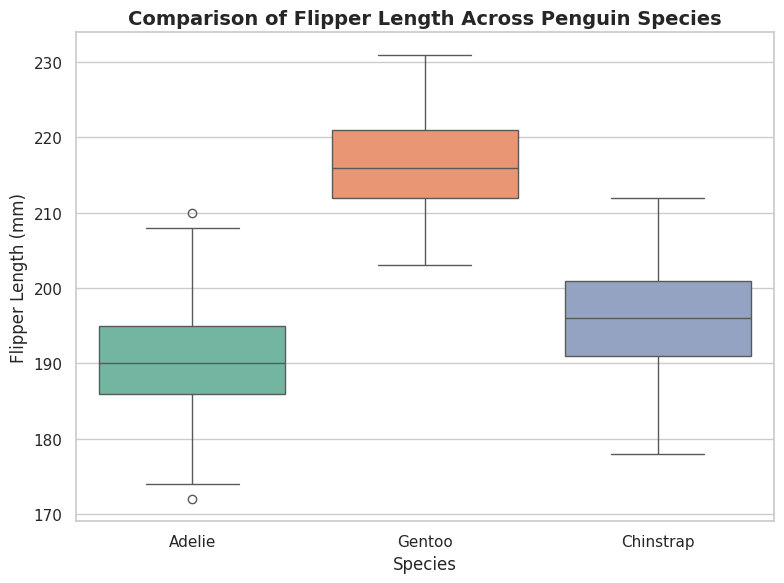

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load the dataset (replace 'penguins.csv' with your actual file path)
df = pd.read_csv("penguins.csv")

# -------------------------------------------------------------
# (1) Summarize missing data
# -------------------------------------------------------------
# Calculate the total count and percentage of missing values per column
missing_summary = pd.DataFrame(
    {
        "missing_count": df.isnull().sum(),
        "missing_percentage": (df.isnull().mean() * 100).round(2),
    }
)

print("=== Missing Data Summary ===")
print(missing_summary[missing_summary["missing_count"] > 0])

# -------------------------------------------------------------
# (2) Compare flipper_length_mm across species
# -------------------------------------------------------------
# Calculate statistical aggregations (mean, median, std, count) grouped by species
print("\n=== Flipper Length Statistics by Species ===")
flipper_stats = (
    df.groupby("species")["flipper_length_mm"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)
print(flipper_stats)

# -------------------------------------------------------------
# (3) Produce one labeled chart
# -------------------------------------------------------------
# Set a clean visual theme for seaborn
sns.set_theme(style="whitegrid")

# Create a figure for the plot
plt.figure(figsize=(8, 6))

# Generate a boxplot comparing flipper length across different species
sns.boxplot(data=df, x="species", y="flipper_length_mm", palette="Set2")

# Add clear labels, title, and formatting
plt.title("Comparison of Flipper Length Across Penguin Species", fontsize=14, fontweight="bold")
plt.xlabel("Species", fontsize=12)
plt.ylabel("Flipper Length (mm)", fontsize=12)

# Adjust layout for clean presentation and display the chart
plt.tight_layout()
plt.show()

In [3]:
df.groupby("species")["flipper_length_mm"].mean()

,flipper_length_mm
species,
Adelie,189.953642
Chinstrap,195.823529
Gentoo,217.186992


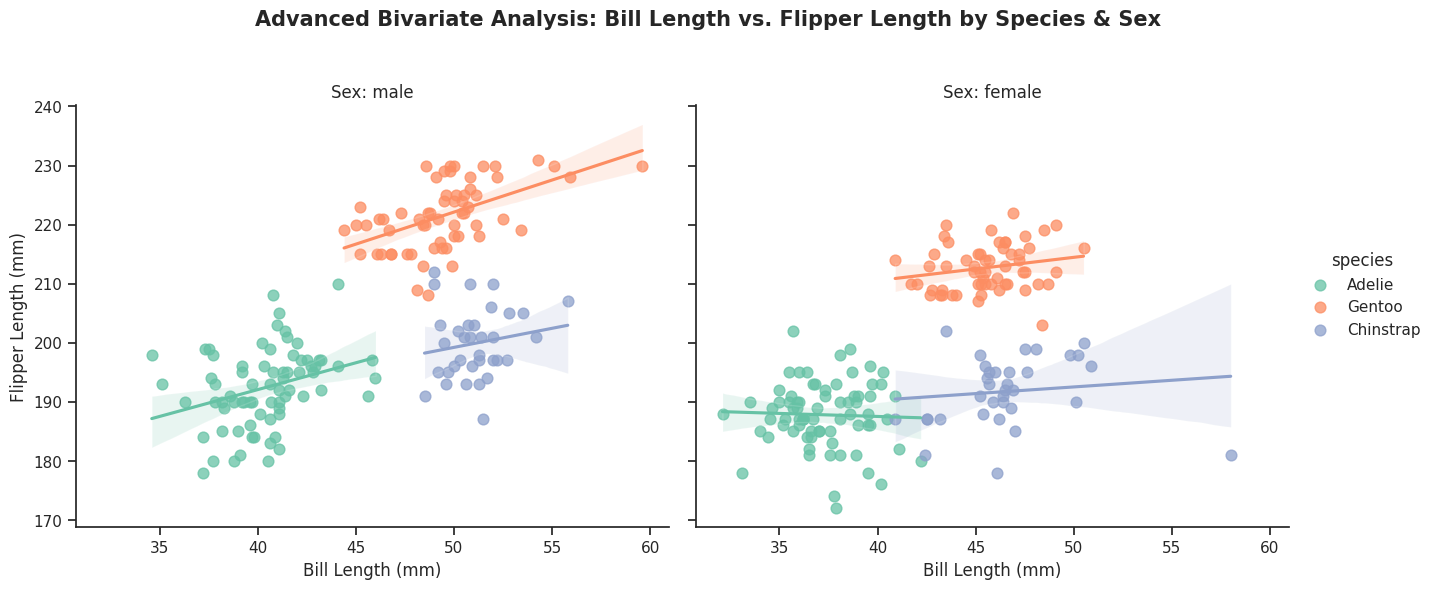

In [4]:
plot_df = df.dropna(
    subset=["bill_length_mm", "flipper_length_mm", "species", "sex"]
).copy()

# Set a professional visual theme
sns.set_theme(style="ticks")

# Create a multi-panel (faceted) scatter plot with regression lines using seaborn's lmplot.
# This powerful chart compares bill length vs. flipper length, grouped by species (via color/hue)
# and split into separate columns by sex (male vs. female).
g = sns.lmplot(
    data=plot_df,
    x="bill_length_mm",
    y="flipper_length_mm",
    hue="species",
    col="sex",
    palette="Set2",
    height=6,
    aspect=1.1,
    scatter_kws={"alpha": 0.75, "s": 60},
)

# Add an overarching title and clean axis labels
g.set_axis_labels("Bill Length (mm)", "Flipper Length (mm)")
g.set_titles(col_template="Sex: {col_name}")
g.fig.subplots_adjust(top=0.82)
g.fig.suptitle(
    "Advanced Bivariate Analysis: Bill Length vs. Flipper Length by Species & Sex",
    fontsize=15,
    fontweight="bold",
)

# Display the finalized chart
plt.show()

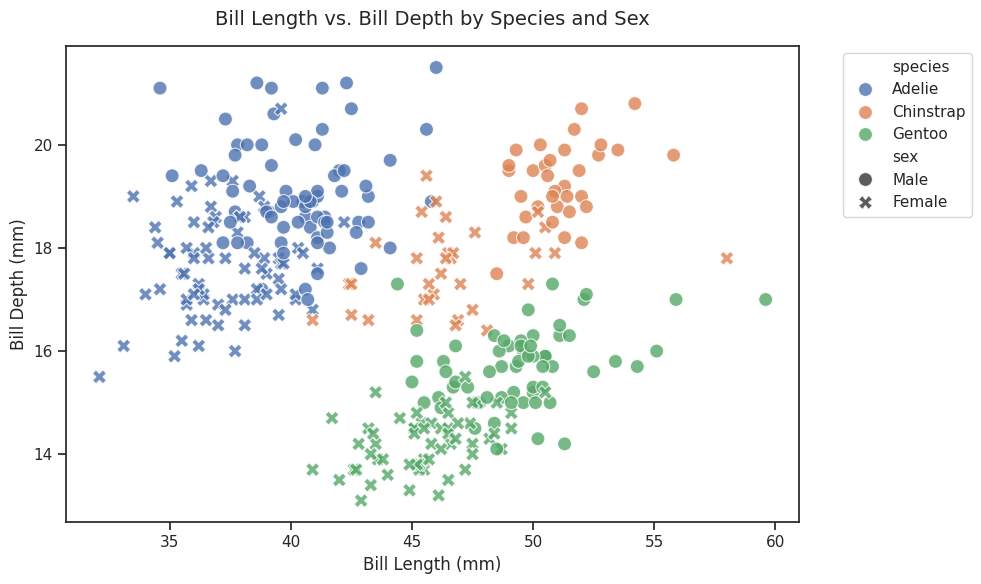

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

df = sns.load_dataset('penguins')

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='species',
    style='sex',
    palette='deep',
    s=100,
    alpha=0.8,
)

plt.title('Bill Length vs. Bill Depth by Species and Sex', fontsize=14, pad=15)
plt.xlabel('Bill Length (mm)', fontsize=12)
plt.ylabel('Bill Depth (mm)', fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### step 7

The AI did not address the relationship between bill length and depth across the different species and sexs. Plotting bill length against bill depth shows that the different species have distinct beak length to depth ratios, with males consistently having larger beaks than females.

### step 8
I would never paste MIMIC-IV patient records into a public ai tool. They are de-identified, but MIMIC-IV is governed by a data-use agreement that restricts sharing. If there are any, I would used an approved internal tool.